In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

URL = "https://previous-runs-api.open-meteo.com/v1/forecast"
HEIGHTS = [10, 80, 100, 120, 180]
base_vars = [f"wind_speed_{h}m" for h in HEIGHTS]
hourly = base_vars + [f"{v}_previous_day1" for v in base_vars]


def fetch(model):
    params = {
        "latitude": 54.07,
        "longitude": 10.30,
        "start_date": "2026-10-12",
        "end_date": "2026-10-18",
        "hourly": ",".join(hourly),
        "models": model,
        "wind_speed_unit": "ms",
        "timezone": "UTC",
    }
    r = requests.get(URL, params=params, timeout=60)
    r.raise_for_status()
    df = pd.DataFrame(r.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"], utc=True)
    return df.set_index("time")


weather = {m: fetch(m) for m in ["icon_seamless", "ecmwf_ifs025"]}

for m, df in weather.items():
    print(m)
    print(df.notna().mean().round(2), "\n")

icon_seamless
wind_speed_10m                   1.0
wind_speed_80m                   1.0
wind_speed_100m                  1.0
wind_speed_120m                  1.0
wind_speed_180m                  1.0
wind_speed_10m_previous_day1     1.0
wind_speed_80m_previous_day1     1.0
wind_speed_100m_previous_day1    1.0
wind_speed_120m_previous_day1    1.0
wind_speed_180m_previous_day1    1.0
dtype: float64 

ecmwf_ifs025
wind_speed_10m                   1.0
wind_speed_80m                   1.0
wind_speed_100m                  1.0
wind_speed_120m                  1.0
wind_speed_180m                  0.0
wind_speed_10m_previous_day1     1.0
wind_speed_80m_previous_day1     1.0
wind_speed_100m_previous_day1    1.0
wind_speed_120m_previous_day1    1.0
wind_speed_180m_previous_day1    0.0
dtype: float64 



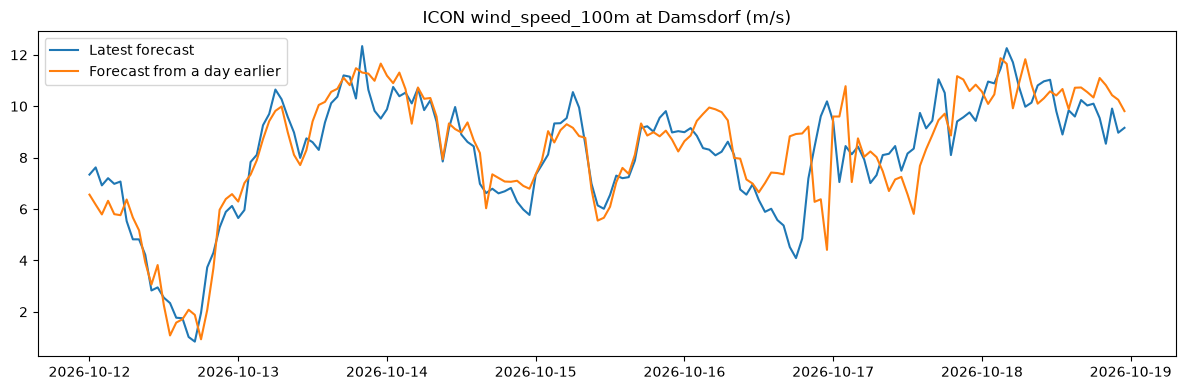

In [2]:
df = weather["icon_seamless"]
h = "wind_speed_100m" if df["wind_speed_100m"].notna().any() else "wind_speed_120m"

plt.figure(figsize=(12, 4))
plt.plot(df.index, df[h], label="Latest forecast")
plt.plot(df.index, df[f"{h}_previous_day1"], label="Forecast from a day earlier")
plt.title(f"ICON {h} at Damsdorf (m/s)")
plt.legend()
plt.tight_layout()

In [3]:
SINGLE_URL = "https://single-runs-api.open-meteo.com/v1/forecast"


def fetch_run(model, run, lat=54.07, lon=10.30, hours=48):
    params = {
        "latitude": lat,
        "longitude": lon,
        "run": run,
        "models": model,
        "hourly": "wind_speed_10m,wind_speed_100m",
        "forecast_hours": hours,
        "wind_speed_unit": "ms",
        "timezone": "UTC",
    }
    r = requests.get(SINGLE_URL, params=params, timeout=60)
    if r.status_code != 200:
        return r.status_code, r.text[:150]
    df = pd.DataFrame(r.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"], utc=True)
    return df.set_index("time")


tests = [
    ("ecmwf_ifs", "2024-03-13T00:00"),
    ("ecmwf_ifs", "2024-03-14T00:00"),
    ("icon_seamless", "2026-04-01T00:00"),
    ("icon_seamless", "2026-04-02T00:00"),
]
for model, run in tests:
    out = fetch_run(model, run)
    if isinstance(out, tuple):
        print(model, run, "-> error", out)
    else:
        print(model, run, "-> ok,", len(out), "hours, first", out.index[0])

ecmwf_ifs 2024-03-13T00:00 -> error (400, '{"error":true,"reason":"The requested model run is not available. Model: ecmwf_ifs, run: 2024-03-13T00:00Z"}')
ecmwf_ifs 2024-03-14T00:00 -> ok, 48 hours, first 2024-03-14 00:00:00+00:00
icon_seamless 2026-04-01T00:00 -> error (400, '{"reason":"The requested model run is not available. Model: dwd_icon_d2_ruc_native_15min, run: 2026-04-01T00:00Z","error":true}')
icon_seamless 2026-04-02T00:00 -> ok, 48 hours, first 2026-04-02 00:00:00+00:00


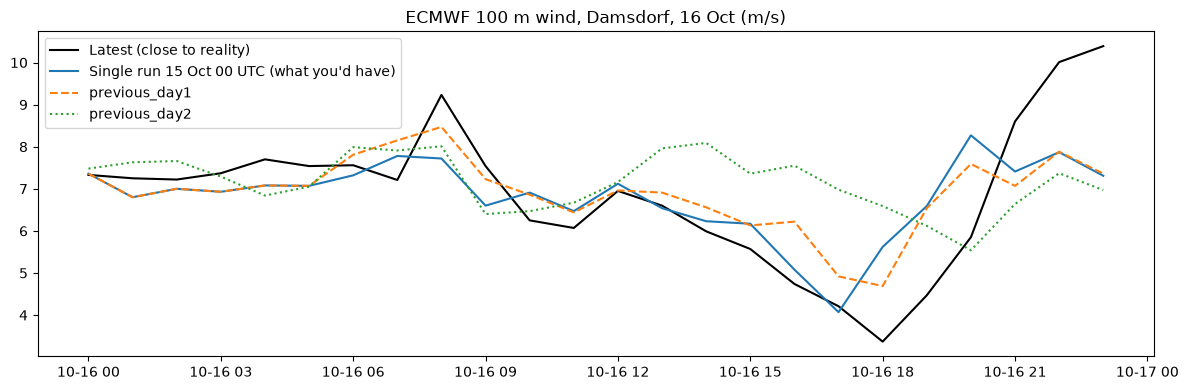

In [4]:
run = fetch_run("ecmwf_ifs", "2026-10-15T00:00")

params = {
    "latitude": 54.07,
    "longitude": 10.30,
    "start_date": "2026-10-16",
    "end_date": "2026-10-16",
    "hourly": "wind_speed_100m,wind_speed_100m_previous_day1,wind_speed_100m_previous_day2",
    "models": "ecmwf_ifs",
    "wind_speed_unit": "ms",
    "timezone": "UTC",
}
prev = pd.DataFrame(requests.get(URL, params=params, timeout=60).json()["hourly"])
prev["time"] = pd.to_datetime(prev["time"], utc=True)
prev = prev.set_index("time")

day16 = run.loc["2026-10-16"]
plt.figure(figsize=(12, 4))
plt.plot(prev.index, prev["wind_speed_100m"], label="Latest (close to reality)", color="black")
plt.plot(day16.index, day16["wind_speed_100m"], label="Single run 15 Oct 00 UTC (what you'd have)")
plt.plot(prev.index, prev["wind_speed_100m_previous_day1"], label="previous_day1", linestyle="--")
plt.plot(prev.index, prev["wind_speed_100m_previous_day2"], label="previous_day2", linestyle=":")
plt.title("ECMWF 100 m wind, Damsdorf, 16 Oct (m/s)")
plt.legend()
plt.tight_layout()

In [5]:
import time

lats = [54.07, 53.50, 52.40, 51.30, 50.10, 53.90, 52.00, 49.50, 51.80, 54.50]
lons = [10.30, 8.50, 12.00, 9.70, 8.00, 13.50, 7.50, 9.00, 11.50, 6.50]

params = {
    "latitude": ",".join(map(str, lats)),
    "longitude": ",".join(map(str, lons)),
    "run": "2026-10-15T00:00",
    "models": "ecmwf_ifs",
    "hourly": "wind_speed_10m,wind_speed_100m",
    "forecast_hours": 48,
    "wind_speed_unit": "ms",
}
t = time.time()
r = requests.get(SINGLE_URL, params=params, timeout=120)
elapsed = time.time() - t
print(
    "Status:",
    r.status_code,
    "| locations returned:",
    len(r.json()),
    "| seconds:",
    round(elapsed, 2),
)

days = (pd.Timestamp("2026-10-27") - pd.Timestamp("2024-03-14")).days
for n_locations in [100, 200, 400]:
    print(f"{n_locations} locations x {days} runs = {n_locations * days:,} location-runs")

Status: 200 | locations returned: 10 | seconds: 0.32
100 locations x 957 runs = 95,700 location-runs
200 locations x 957 runs = 191,400 location-runs
400 locations x 957 runs = 382,800 location-runs
